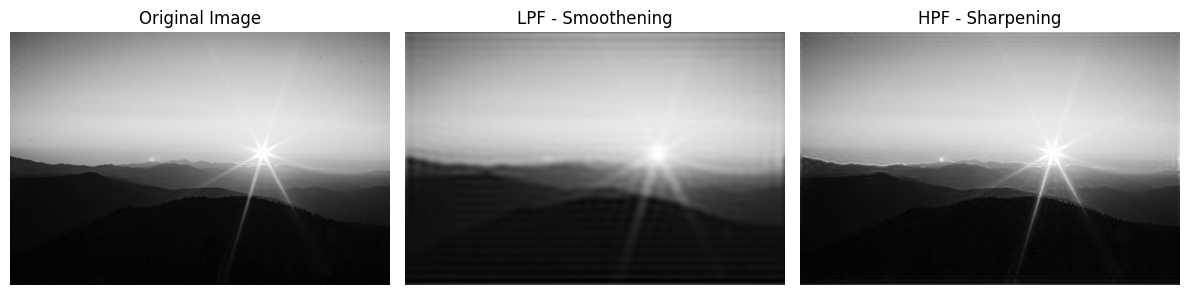

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read image from the project folder
img = cv2.imread("exp_10_image.jpg", 0)

# Check if image is loaded
if img is None:
    print("Error: Image not found!")
    exit()

# 2. Fourier Transform
F = np.fft.fftshift(np.fft.fft2(img))

# Get image dimensions
M, N = img.shape

# 3. Create frequency distance matrix
u, v = np.meshgrid(
    np.arange(N) - N // 2,
    np.arange(M) - M // 2
)

D = np.sqrt(u**2 + v**2)

# 4. Create Low-Pass and High-Pass Filters
LPF = D < 30
HPF = D >= 30

# 5. Apply Low-Pass Filter
smooth = np.abs(
    np.fft.ifft2(
        np.fft.ifftshift(F * LPF)
    )
)

# 6. Apply High-Pass Filter
high_pass = np.abs(
    np.fft.ifft2(
        np.fft.ifftshift(F * HPF)
    )
)

# 7. Sharpen the image
sharp = np.clip(
    img.astype(float) + high_pass,
    0,
    255
)

# 8. Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap="gray")
plt.title("LPF - Smoothening")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap="gray")
plt.title("HPF - Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()